In [1]:
#Inicialización de la estructura del proyecto

from pathlib import Path

# Directorio principal del proyecto
PROJECT_DIR = Path("/content/scout")

# Estructura inicial
carpetas = [
    "data/futdataset",
    "models",
    "src",
    "notebooks",
    "outputs/videos",
    "outputs/detections",
    "config",
]

for carpeta in carpetas:
    (PROJECT_DIR / carpeta).mkdir(parents=True, exist_ok=True)

# Archivos iniciales
archivos = {
    "src/__init__.py": "",
    "requirements.txt": "",
    "README.md": "# Scout\nProyecto de detección y reidentificación de jugadores.",
    "config/config.yaml": "# Configuración del proyecto\n",
}

for ruta, contenido in archivos.items():
    archivo = PROJECT_DIR / ruta
    if not archivo.exists():
        archivo.write_text(contenido, encoding="utf-8")

print("Estructura creada correctamente:")
for ruta in sorted(PROJECT_DIR.rglob("*")):
    print(ruta.relative_to(PROJECT_DIR))

Estructura creada correctamente:
README.md
config
config/config.yaml
data
data/futdataset
models
notebooks
outputs
outputs/detections
outputs/videos
requirements.txt
src
src/__init__.py


In [2]:

# ==================================================
# INSTALAR DEPENDENCIAS
# ==================================================

%pip install -q roboflow ultralytics opencv-python-headless pandas pyyaml matplotlib "supervision>=0.23.0"
%pip install -q trackers

In [3]:

# ==================================================
# 02 — VERIFICACIÓN DEL ENTORNO
# ==================================================

import torch
import ultralytics
import cv2
import pandas as pd
import roboflow
import yaml
import matplotlib
import supervision as sv

from pathlib import Path
from ultralytics import YOLO
from trackers import ByteTrackTracker

print("Supervision:", sv.__version__)
print("ByteTrackTracker disponible:", ByteTrackTracker)
print("BoxAnnotator disponible:", hasattr(sv, "BoxAnnotator"))

print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Supervision:", sv.__version__)

print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Todas las importaciones se completaron correctamente.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Supervision: 0.31.3
ByteTrackTracker disponible: <class 'trackers.core.bytetrack.tracker.ByteTrackTracker'>
BoxAnnotator disponible: True
Ultralytics: 8.4.192
OpenCV: 5.0.0
Pandas: 2.2.3
PyTorch: 2.11.0+cu130
Matplotlib: 3.10.0
Supervision: 0.31.3
GPU disponible: True
GPU: Tesla T4
Todas las importaciones se completaron correctamente.


In [4]:
from pathlib import Path

PROJECT_DIR = Path("/content/scout")

print("¿Existe el proyecto?", PROJECT_DIR.exists())
print("\nContenido de /content/scout:")

for ruta in sorted(PROJECT_DIR.rglob("*")):
    if ruta.is_file():
        print("ARCHIVO:", ruta.relative_to(PROJECT_DIR))
    elif ruta.is_dir():
        print("CARPETA:", ruta.relative_to(PROJECT_DIR))

¿Existe el proyecto? True

Contenido de /content/scout:
ARCHIVO: README.md
CARPETA: config
ARCHIVO: config/config.yaml
CARPETA: data
CARPETA: data/futdataset
CARPETA: models
CARPETA: notebooks
CARPETA: outputs
CARPETA: outputs/detections
CARPETA: outputs/videos
ARCHIVO: requirements.txt
CARPETA: src
ARCHIVO: src/__init__.py


In [5]:
from google.colab import userdata
from roboflow import Roboflow
from pathlib import Path

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

api_key = userdata.get("ROBOFLOW_API_KEY")

if not api_key:
    raise ValueError("No se encontró el secreto ROBOFLOW_API_KEY.")

rf = Roboflow(api_key=api_key)
project = rf.workspace("futdataset").project("futdataset")
version = project.version(2)

dataset = version.download(
    "yolov8",
    location=str(DATASET_DIR)
)

print("\nRuta devuelta por Roboflow:", dataset.location)

ruta_descargada = Path(dataset.location)
print("\nArchivos encontrados:")

for ruta in sorted(ruta_descargada.rglob("*")):
    if ruta.is_file():
        print(ruta.relative_to(ruta_descargada))

loading Roboflow workspace...
loading Roboflow project...

Ruta devuelta por Roboflow: /content/scout/data/futdataset

Archivos encontrados:


In [6]:
# Consultar los metadatos de la versión
print("Proyecto:", project.name)
print("Versión:", version.version)

print("\nInformación de la versión:")
print(version)

Proyecto: FutDataset
Versión: 2

Información de la versión:
{
  "name": "FutDataset",
  "type": "object-detection",
  "version": "2",
  "augmentation": {},
  "created": 1755269838.954,
  "preprocessing": {
    "auto-orient": true,
    "resize": {
      "format": "Stretch to",
      "height": 640,
      "width": 640
    }
  },
  "splits": {
    "valid": 102,
    "test": 52,
    "train": 357
  },
  "workspace": "futdataset"
}


In [7]:
#Descargar el dataset y comprobar sus archivos
from pathlib import Path
from roboflow import Roboflow
from google.colab import userdata

api_key = userdata.get("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)

project = rf.workspace("futdataset").project("futdataset")
version = project.version(2)

# Descargar en una carpeta nueva para diagnosticar
DATASET_DIR = Path("/content/scout/data/futdataset_v2")

dataset = version.download(
    model_format="yolov8",
    location=str(DATASET_DIR),
    overwrite=True
)

print("\nRuta devuelta:", dataset.location)

ruta = Path(dataset.location)
archivos = [p for p in ruta.rglob("*") if p.is_file()]

print("Total de archivos encontrados:", len(archivos))
for archivo in archivos[:30]:
    print(archivo.relative_to(ruta))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/scout/data/futdataset_v2 in yolov8:: 100%|██████████| 1034/1034 [00:00<00:00, 3533.85it/s]



Ruta devuelta: /content/scout/data/futdataset_v2
Total de archivos encontrados: 1025
data.yaml
README.dataset.txt
README.roboflow.txt
train/images/GOMCAM-20250704_2113590680_png.rf.d901ff46a943c02f06861a34d9dedbed.jpg
train/images/GOMCAM-20250807_1628430913_png.rf.f3d178afb0ed7d017dbca859b1a5a757.jpg
train/images/GOMCAM-20250704_2102490042_png.rf.8ddc3cfe2a5b80f2f40c2f172211e9a8.jpg
train/images/GOMCAM-20250704_2127180521_png.rf.04267e0adcea19fb15a2ee1985a353ef.jpg
train/images/GOMCAM-20250704_2055170918_png.rf.d940e49e4ed5e22901e38f7fdfe8c99d.jpg
train/images/GOMCAM-20250712_2159490433_png.rf.48c2fcaa4c09f2da7f4d0cbcf9466fec.jpg
train/images/GOMCAM-20250706_2222390270_png.rf.23e777312b87590e38abe314dd0272db.jpg
train/images/GOMCAM-20250708_2212500538_png.rf.3e49a1059891303adc0f5d8d3fcd0a08.jpg
train/images/GOMCAM-20250704_2114140408_png.rf.60c4b46861e3a93af558e386dd6843b7.jpg
train/images/GOMCAM-20250709_2225420676_png.rf.395badf80f64eea5e5563d611bbfb33e.jpg
train/images/GOMCAM-20250

In [8]:
#Validar el dataset
from pathlib import Path
import yaml

DATASET_DIR = Path("/content/scout/data/futdataset_v2")
DATA_YAML = DATASET_DIR / "data.yaml"

# 1. Verificar el archivo de configuración
if not DATA_YAML.exists():
    raise FileNotFoundError(f"No se encontró: {DATA_YAML}")

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("=== CONFIGURACIÓN DEL DATASET ===")
print(yaml.dump(config, allow_unicode=True, sort_keys=False))

# 2. Contar imágenes por conjunto
print("\n=== IMÁGENES ===")

for split in ["train", "valid", "test"]:
    carpeta = DATASET_DIR / split / "images"

    if carpeta.exists():
        imagenes = [
            p for p in carpeta.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]
        print(f"{split}: {len(imagenes)} imágenes")
    else:
        print(f"{split}: NO SE ENCONTRÓ LA CARPETA {carpeta}")

# 3. Comprobar las etiquetas
print("\n=== ETIQUETAS YOLO ===")

for split in ["train", "valid", "test"]:
    carpeta = DATASET_DIR / split / "labels"

    if carpeta.exists():
        etiquetas = list(carpeta.glob("*.txt"))
        print(f"{split}: {len(etiquetas)} archivos de etiquetas")
    else:
        print(f"{split}: NO SE ENCONTRÓ LA CARPETA DE ETIQUETAS")

=== CONFIGURACIÓN DEL DATASET ===
names:
- arbitro
- arquero1
- arquero2
- ball
- equipo1
- equipo2
nc: 6
roboflow:
  license: CC BY 4.0
  project: futdataset
  url: https://universe.roboflow.com/futdataset/futdataset/dataset/2
  version: 2
  workspace: futdataset
test: ../test/images
train: ../train/images
val: ../valid/images


=== IMÁGENES ===
train: 357 imágenes
valid: 102 imágenes
test: 52 imágenes

=== ETIQUETAS YOLO ===
train: 357 archivos de etiquetas
valid: 102 archivos de etiquetas
test: 52 archivos de etiquetas


In [9]:
#5. Crear el primer módulo de detección
from pathlib import Path

PROJECT_DIR = Path("/content/scout")
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

codigo = """
from pathlib import Path

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
DATA_YAML = DATASET_DIR / "data.yaml"
MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"


def verificar_dataset():
    if not DATA_YAML.exists():
        raise FileNotFoundError(
            f"No se encontró el archivo: {DATA_YAML}"
        )

    print("Dataset encontrado:", DATA_YAML)
    print("Configuración disponible para entrenar.")


if __name__ == "__main__":
    verificar_dataset()
"""

archivo = SRC_DIR / "detector.py"
archivo.write_text(codigo, encoding="utf-8")

print("Módulo creado:", archivo)
print("Existe data.yaml:", (PROJECT_DIR / "data/futdataset_v2/data.yaml").exists())
print("Existe detector.py:", archivo.exists())

exec(compile(codigo, str(archivo), "exec"))

Módulo creado: /content/scout/src/detector.py
Existe data.yaml: True
Existe detector.py: True
Dataset encontrado: /content/scout/data/futdataset_v2/data.yaml
Configuración disponible para entrenar.


Imagen: GOMCAM-20250704_2055560194_png.rf.bbc02c32e161a6751739e7bb8e619aaa.jpg
Dimensiones: 640 x 640
Etiqueta encontrada: True


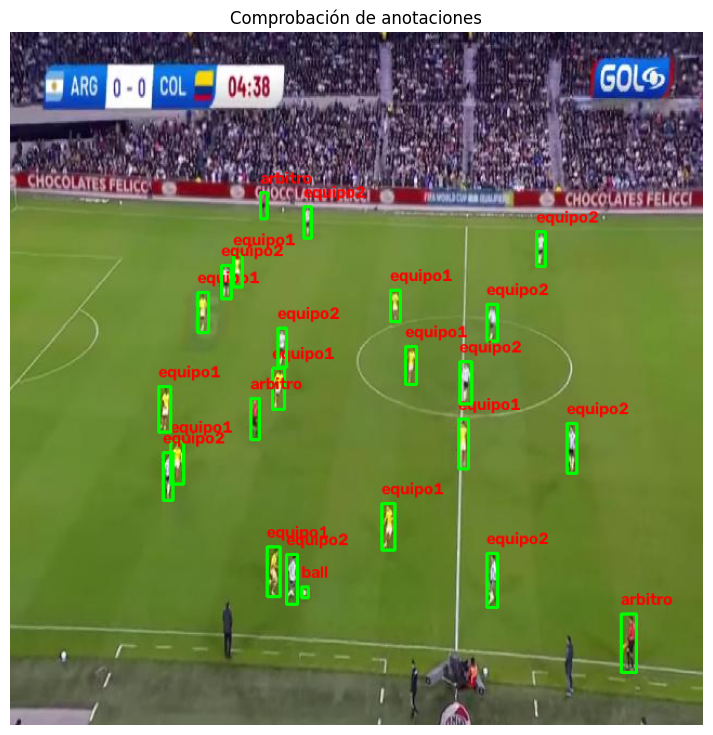

In [10]:
#Visualizar las anotaciones del dataset
from pathlib import Path
import cv2
import yaml
import matplotlib.pyplot as plt
import random

DATASET_DIR = Path("/content/scout/data/futdataset_v2")

with open(DATASET_DIR / "data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
images_dir = DATASET_DIR / "train" / "images"
labels_dir = DATASET_DIR / "train" / "labels"

images = [
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

if not images:
    raise FileNotFoundError("No se encontraron imágenes de entrenamiento.")

image_path = random.choice(images)
label_path = labels_dir / f"{image_path.stem}.txt"

image = cv2.imread(str(image_path))
if image is None:
    raise ValueError(f"No se pudo leer la imagen: {image_path}")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]

print("Imagen:", image_path.name)
print("Dimensiones:", width, "x", height)
print("Etiqueta encontrada:", label_path.exists())

if label_path.exists():
    with open(label_path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()
        if len(parts) != 5:
            print("Etiqueta con formato inesperado:", line.strip())
            continue

        class_id, x_center, y_center, box_w, box_h = map(float, parts)
        class_id = int(class_id)

        x1 = int((x_center - box_w / 2) * width)
        y1 = int((y_center - box_h / 2) * height)
        x2 = int((x_center + box_w / 2) * width)
        y2 = int((y_center + box_h / 2) * height)

        nombre = names[class_id] if 0 <= class_id < len(names) else f"clase_{class_id}"

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            image, nombre, (x1, max(y1 - 8, 15)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2
        )

plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.axis("off")
plt.title("Comprobación de anotaciones")
plt.show()

In [11]:
#Preparar el entrenamiento de YOLO
from pathlib import Path
import yaml
import torch
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
DATA_YAML = DATASET_DIR / "data.yaml"

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("Clases:", config["names"])
print("Número de clases:", config["nc"])
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Dataset listo:", DATA_YAML.exists())
print("Carpeta de modelos:", (PROJECT_DIR / "models").exists())
print("Carpeta de resultados:", (PROJECT_DIR / "outputs").exists())

Clases: ['arbitro', 'arquero1', 'arquero2', 'ball', 'equipo1', 'equipo2']
Número de clases: 6
GPU disponible: True
GPU: Tesla T4
Dataset listo: True
Carpeta de modelos: True
Carpeta de resultados: True


In [12]:
#Entrenar el modelo
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path("/content/scout")
DATA_YAML = PROJECT_DIR / "data" / "futdataset_v2" / "data.yaml"

# Modelo preentrenado
model = YOLO("yolov8s.pt")

# Entrenamiento inicial
results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project=str(PROJECT_DIR / "outputs"),
    name="deteccion_v1",
    exist_ok=True,
    patience=10,
    save=True,
    plots=True,
    seed=42
)

print("\nEntrenamiento finalizado.")
print("Resultados:", PROJECT_DIR / "outputs" / "deteccion_v1")
print("Mejor modelo:", PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/scout/data/futdataset_v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=deteccion_v1, nbs=64, nms=None, opset=None, op

Results saved to /content/scout/outputs/prueba_visual
Imagen: GOMCAM-20250704_2051270247_png.rf.0c6dccea6f06e2dcac09fcd4ae52b50b.jpg
Detecciones: 18


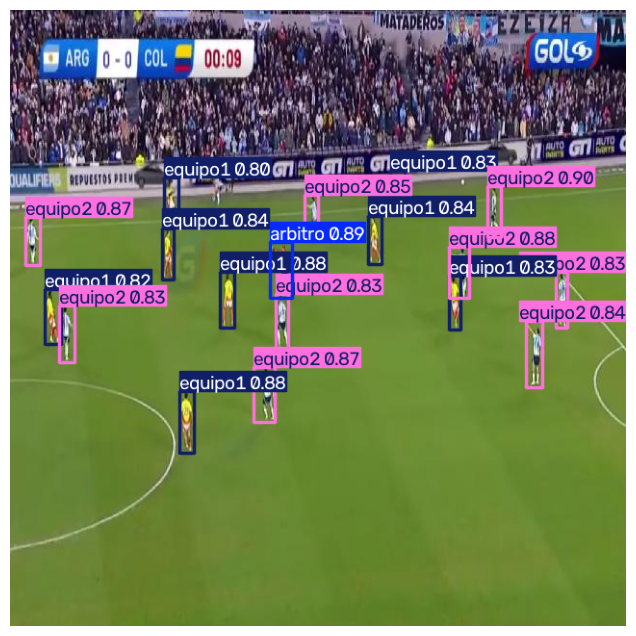

Imagen: GOMCAM-20250807_1626510822_png.rf.99a3f8ebf54718425531d2421e99b508.jpg
Detecciones: 23


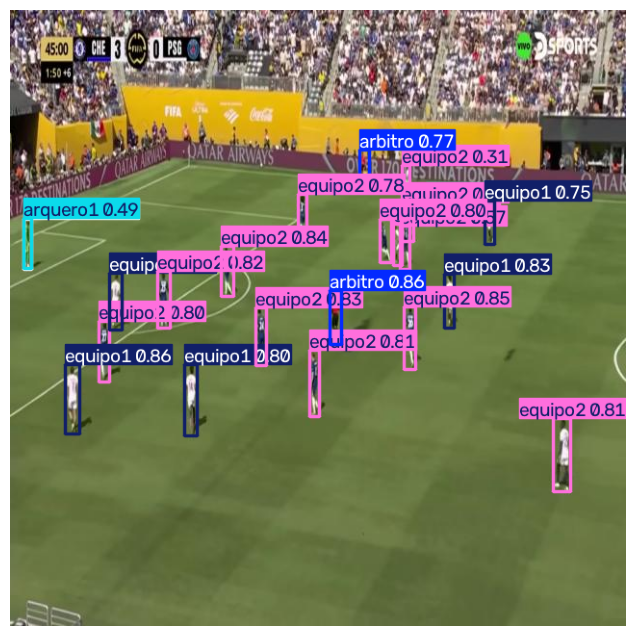

Imagen: GOMCAM-20250704_2114270425_png.rf.b4334a0fc6ff3c4877c714141cd81fe7.jpg
Detecciones: 14


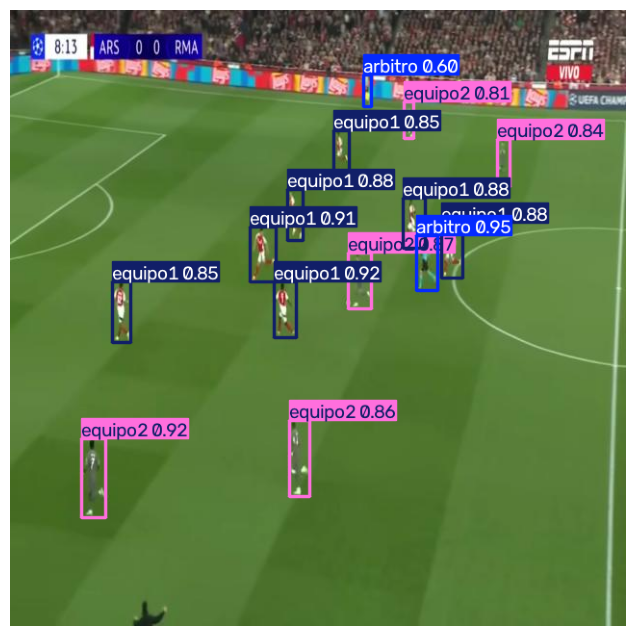

Predicciones guardadas en: /content/scout/outputs/prueba_visual


In [13]:
#9 Probar el modelo con imágenes que no ha visto
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
MODEL_PATH = PROJECT_DIR / "outputs/deteccion_v1/weights/best.pt"
TEST_DIR = PROJECT_DIR / "data/futdataset_v2/test/images"

model = YOLO(str(MODEL_PATH))

imagenes = [
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

if len(imagenes) < 3:
    raise ValueError(f"Solo se encontraron {len(imagenes)} imágenes de prueba.")

seleccionadas = random.sample(imagenes, 3)

resultados = model.predict(
    source=[str(p) for p in seleccionadas],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(PROJECT_DIR / "outputs"),
    name="prueba_visual",
    exist_ok=True,
    verbose=False
)

for resultado in resultados:
    imagen = resultado.plot()
    imagen = imagen[:, :, ::-1]  # BGR a RGB

    print("Imagen:", Path(resultado.path).name)
    print("Detecciones:", len(resultado.boxes))

    plt.figure(figsize=(14, 8))
    plt.imshow(imagen)
    plt.axis("off")
    plt.show()

print("Predicciones guardadas en:",
      PROJECT_DIR / "outputs" / "prueba_visual")

In [14]:
#comprobar si el modelo detecta algún balón
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
MODEL_PATH = PROJECT_DIR / "outputs/deteccion_v1/weights/best.pt"
TEST_DIR = PROJECT_DIR / "data/futdataset_v2/test/images"

model = YOLO(str(MODEL_PATH))

imagenes = [
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

print("Total de imágenes:", len(imagenes))
print("Clase del balón:", {
    k: v for k, v in model.names.items() if v == "ball"
})

for umbral in [0.05, 0.10, 0.25]:
    imagenes_con_balon = 0
    total_balones = 0

    for ruta in imagenes:
        resultado = model.predict(
            source=str(ruta),
            imgsz=640,
            conf=umbral,
            device=0,
            verbose=False
        )[0]

        if resultado.boxes is not None:
            clases = resultado.boxes.cls.cpu().tolist()
            cantidad = sum(
                1 for clase in clases
                if model.names[int(clase)] == "ball"
            )
            total_balones += cantidad

            if cantidad > 0:
                imagenes_con_balon += 1

    print(
        f"Umbral {umbral:.2f} | "
        f"Imágenes con balón: {imagenes_con_balon} | "
        f"Detecciones de balón: {total_balones}"
    )

Total de imágenes: 52
Clase del balón: {3: 'ball'}
Umbral 0.05 | Imágenes con balón: 34 | Detecciones de balón: 60
Umbral 0.10 | Imágenes con balón: 31 | Detecciones de balón: 39
Umbral 0.25 | Imágenes con balón: 24 | Detecciones de balón: 27


Clases: ['arbitro', 'arquero1', 'arquero2', 'ball', 'equipo1', 'equipo2']
Imágenes anotadas con balón: 309
Imagen: GOMCAM-20250706_2216350970_png.rf.952e81f4d67a1e65daf1d4254b8877c9.jpg


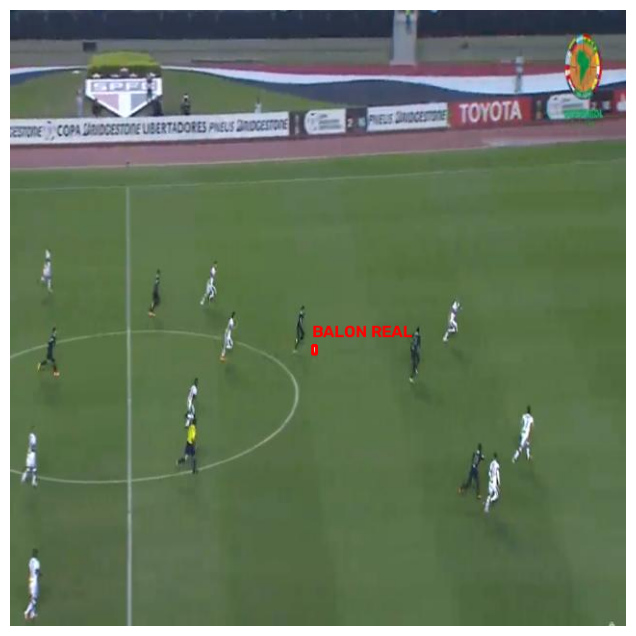

Imagen: GOMCAM-20250709_2238280343_png.rf.e9273aba9754b67c2df0f89c00ef0668.jpg


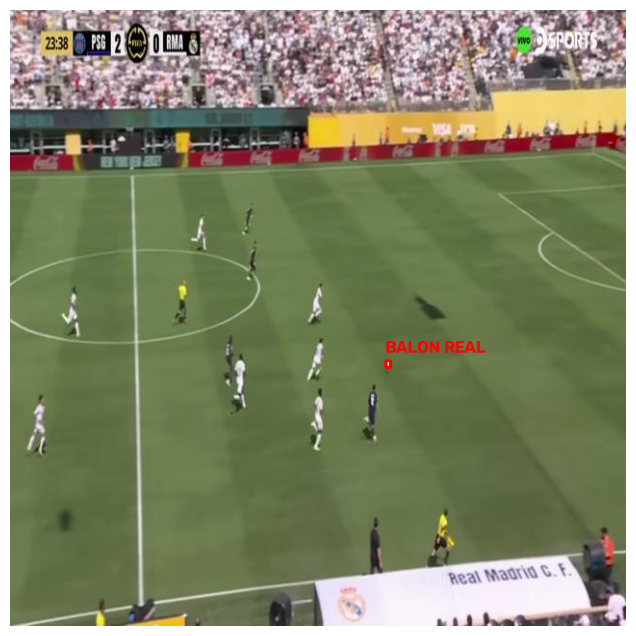

Imagen: GOMCAM-20250709_2238040229_png.rf.63f7ea83c90c744b585d8f5f2805bfe1.jpg


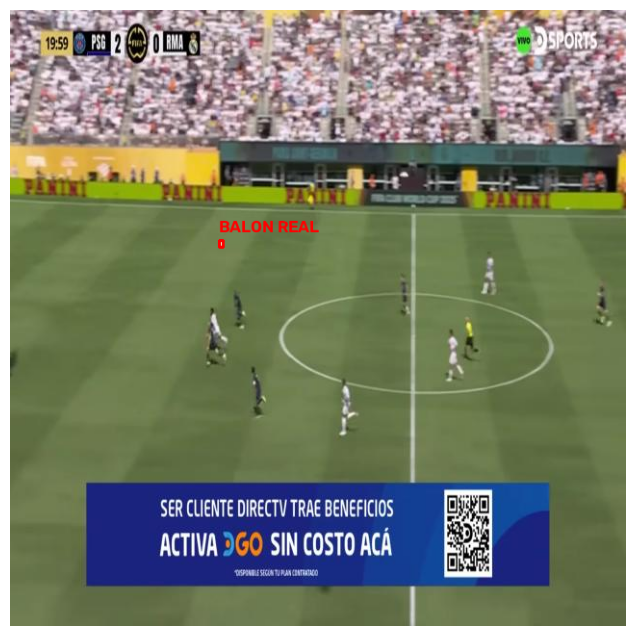

In [15]:
#verificar las anotaciones reales del balón
from pathlib import Path
import yaml
import cv2
import matplotlib.pyplot as plt
import random

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"

with open(DATASET_DIR / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("Clases:", config["names"])

images_dir = DATASET_DIR / "train" / "images"
labels_dir = DATASET_DIR / "train" / "labels"

imagenes_con_balon = []

for etiqueta in labels_dir.glob("*.txt"):
    with open(etiqueta, "r") as f:
        lineas = f.readlines()

    if any(linea.split()[0] == "3" for linea in lineas if linea.strip()):
        imagen = images_dir / f"{etiqueta.stem}.jpg"

        if not imagen.exists():
            for extension in [".png", ".jpeg", ".webp"]:
                alternativa = images_dir / f"{etiqueta.stem}{extension}"
                if alternativa.exists():
                    imagen = alternativa
                    break

        if imagen.exists():
            imagenes_con_balon.append((imagen, etiqueta))

print("Imágenes anotadas con balón:", len(imagenes_con_balon))

for imagen_path, etiqueta_path in random.sample(
    imagenes_con_balon, min(3, len(imagenes_con_balon))
):
    imagen = cv2.imread(str(imagen_path))
    alto, ancho = imagen.shape[:2]

    with open(etiqueta_path, "r") as f:
        for linea in f:
            datos = linea.split()
            if len(datos) != 5 or datos[0] != "3":
                continue

            _, xc, yc, w, h = map(float, datos)
            x1 = int((xc - w / 2) * ancho)
            y1 = int((yc - h / 2) * alto)
            x2 = int((xc + w / 2) * ancho)
            y2 = int((yc + h / 2) * alto)

            cv2.rectangle(imagen, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(
                imagen, "BALON REAL",
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2
            )

    print("Imagen:", imagen_path.name)
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

In [16]:
#Celda de diagnóstico
#Esta celda compara las anotaciones reales con las predicciones del modelo en las 52 imágenes de prueba.

from pathlib import Path
import yaml
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

with open(DATASET_DIR / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

# Funciona tanto si names es una lista como si es un diccionario
if isinstance(names, list):
    ball_id = names.index("ball")
else:
    ball_id = next(int(k) for k, v in names.items() if v == "ball")

print("Clases:", names)
print("ID del balón:", ball_id)

model = YOLO(str(MODEL_PATH))

metrics = model.val(
    data=str(DATASET_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.50,
    plots=True,
    project=str(PROJECT_DIR / "outputs"),
    name="diagnostico_balon",
    exist_ok=True,
    verbose=False
)

print("\n--- MÉTRICAS DEL BALÓN EN TEST ---")
print("Precisión:", round(float(metrics.box.p[ball_id]), 3))
print("Recall:", round(float(metrics.box.r[ball_id]), 3))
print("mAP50:", round(float(metrics.box.ap50[ball_id]), 3))
print("mAP50-95:", round(float(metrics.box.ap[ball_id]), 3))

print("\nResultados guardados en:")
print(PROJECT_DIR / "outputs" / "diagnostico_balon")

Clases: ['arbitro', 'arquero1', 'arquero2', 'ball', 'equipo1', 'equipo2']
ID del balón: 3
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1639.2±464.9 MB/s, size: 41.6 KB)
val: Scanning /content/scout/data/futdataset_v2/test/labels... 52 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 1.6Kit/s 0.0s
val: New cache created: /content/scout/data/futdataset_v2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0it/s 3.9s
                   all         52        929      0.941      0.828       0.87      0.634
Speed: 7.1ms preprocess, 14.7ms inference, 0.1ms loss, 20.2ms postprocess per image
Results saved to /content/scout/outputs/diagnostico_balon

--- MÉTRICAS DEL BALÓN EN TEST ---
Precisión: 0.982
Recall: 0.37
mAP50: 0.511
mAP50-95: 0

Imagen: GOMCAM-20250708_2217380577_png.rf.293c750eaa298e9bf1db7a22798512bc.jpg
Caja original del balón: 4 × 5 píxeles


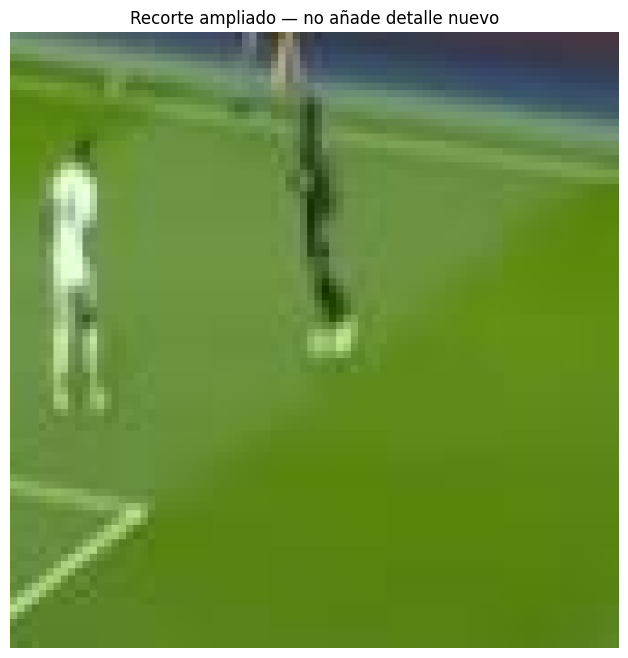

Imagen: GOMCAM-20250704_2102020642_png.rf.be93dd9fb8b004516100dff27e2658a6.jpg
Caja original del balón: 7 × 10 píxeles


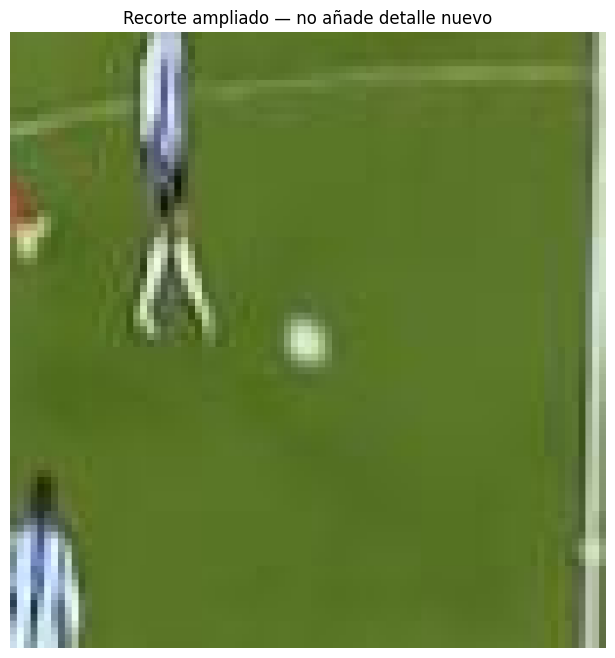

Imagen: GOMCAM-20250705_2047570968_png.rf.102099e0ff61e54a5bc449209f230f5a.jpg
Caja original del balón: 5 × 7 píxeles


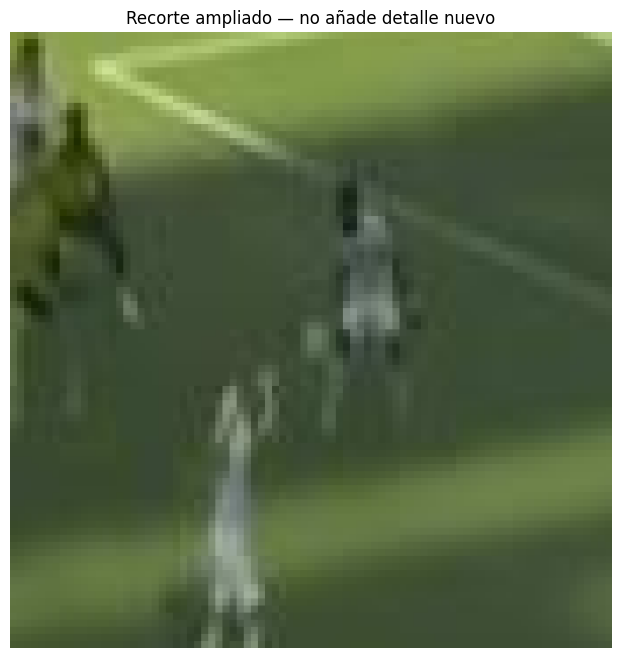

In [17]:
#ejemplo visualizar el balón ampliado
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"

images_dir = DATASET_DIR / "train" / "images"
labels_dir = DATASET_DIR / "train" / "labels"
ball_id = 3

candidatas = []

for label_path in labels_dir.glob("*.txt"):
    lineas = [
        linea.split()
        for linea in label_path.read_text().splitlines()
        if linea.strip()
    ]

    balones = [
        datos for datos in lineas
        if len(datos) == 5 and int(datos[0]) == ball_id
    ]

    if not balones:
        continue

    image_path = next(
        (images_dir / f"{label_path.stem}{ext}"
         for ext in [".jpg", ".jpeg", ".png", ".webp"]
         if (images_dir / f"{label_path.stem}{ext}").exists()),
        None
    )

    if image_path:
        candidatas.append((image_path, balones))

seleccionadas = random.sample(candidatas, min(3, len(candidatas)))

for image_path, balones in seleccionadas:
    imagen = cv2.imread(str(image_path))
    alto, ancho = imagen.shape[:2]

    # Seleccionar la primera anotación del balón
    _, xc, yc, w, h = map(float, balones[0])

    x1 = int((xc - w / 2) * ancho)
    y1 = int((yc - h / 2) * alto)
    x2 = int((xc + w / 2) * ancho)
    y2 = int((yc + h / 2) * alto)

    # Recorte ampliado con margen alrededor del balón
    margen = 40
    xa, ya = max(0, x1 - margen), max(0, y1 - margen)
    xb, yb = min(ancho, x2 + margen), min(alto, y2 + margen)

    recorte = imagen[ya:yb, xa:xb]
    ampliado = cv2.resize(
        recorte, None, fx=6, fy=6,
        interpolation=cv2.INTER_NEAREST
    )

    print("Imagen:", image_path.name)
    print("Caja original del balón:", x2 - x1, "×", y2 - y1, "píxeles")

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(ampliado, cv2.COLOR_BGR2RGB))
    plt.title("Recorte ampliado — no añade detalle nuevo")
    plt.axis("off")
    plt.show()

In [18]:
#comprobar nuestro entorno antes de instalar nada
import torch
import ultralytics
import cv2

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)

try:
    import supervision as sv
    print("Supervision:", sv.__version__)
except ImportError:
    print("Supervision: no está instalado")

try:
    import inference
    print("Inference: instalado")
except ImportError:
    print("Inference: no está instalado")

PyTorch: 2.11.0+cu130
CUDA disponible: True
Ultralytics: 8.4.192
OpenCV: 5.0.0
Supervision: 0.31.3
Inference: no está instalado


Imágenes de prueba: 52
Imágenes con balón anotado: 46


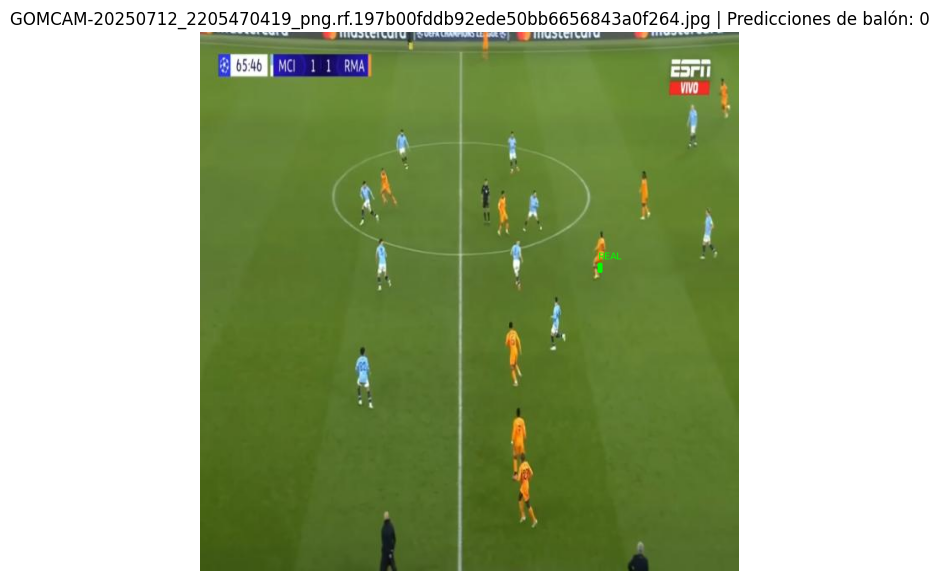

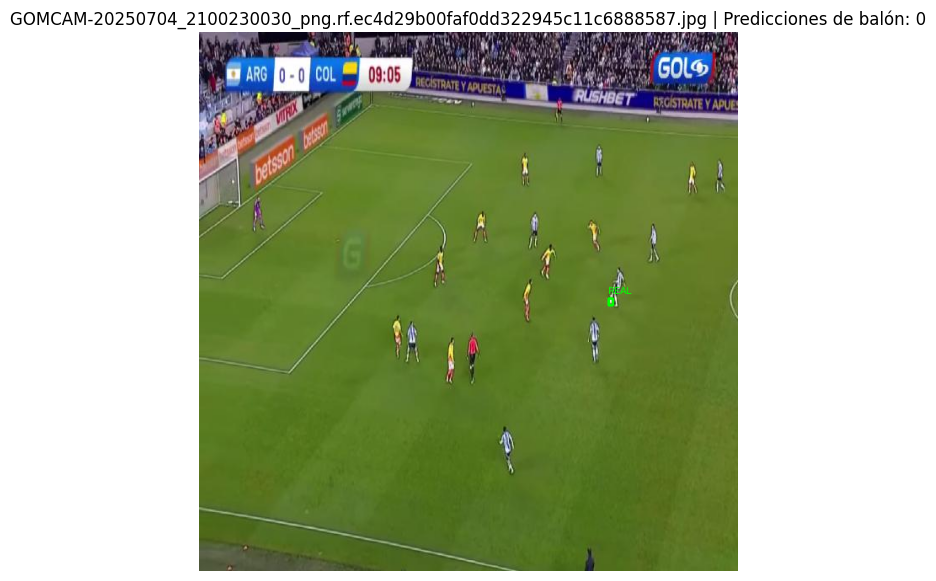

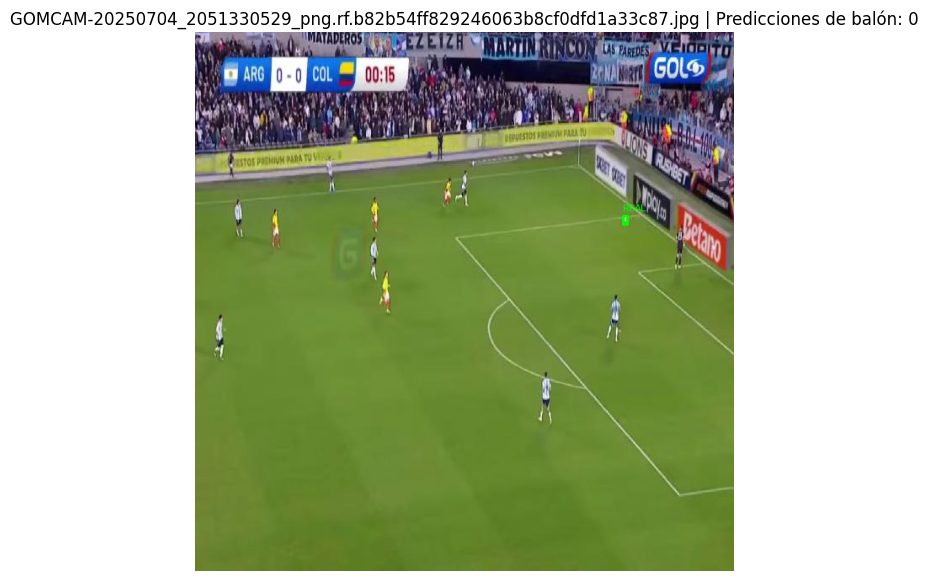

Verde = anotación real | Azul/rojo = predicción del modelo


In [19]:
#Comparar el balón real con las predicciones

# ==================================================
# PASO 1 — DIAGNÓSTICO VISUAL DEL BALÓN
# ==================================================

from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

TEST_IMAGES = DATASET_DIR / "test" / "images"
TEST_LABELS = DATASET_DIR / "test" / "labels"

assert MODEL_PATH.exists(), f"No se encuentra el modelo: {MODEL_PATH}"
assert TEST_IMAGES.exists(), f"No se encuentra el directorio: {TEST_IMAGES}"

model = YOLO(str(MODEL_PATH))

# Seleccionar imágenes de prueba que tengan anotación real del balón
image_paths = sorted(
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

ball_images = []

for image_path in image_paths:
    label_path = TEST_LABELS / f"{image_path.stem}.txt"

    if label_path.exists():
        lines = label_path.read_text().splitlines()
        if any(line.split() and line.split()[0] == "3" for line in lines):
            ball_images.append(image_path)

print("Imágenes de prueba:", len(image_paths))
print("Imágenes con balón anotado:", len(ball_images))

random.seed(42)
selected = random.sample(ball_images, min(3, len(ball_images)))

for image_path in selected:
    image_bgr = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = image_rgb.shape[:2]

    # Copia para dibujar la anotación real en verde
    annotated = image_rgb.copy()
    label_path = TEST_LABELS / f"{image_path.stem}.txt"

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5 or parts[0] != "3":
            continue

        _, xc, yc, bw, bh = map(float, parts[:5])
        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            annotated, "REAL",
            (x1, max(12, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1
        )

    # Predecir con confianza baja para observar más candidatos
    result = model.predict(
        source=image_rgb,
        imgsz=640,
        conf=0.05,
        verbose=False
    )[0]

    predicted_balls = 0

    for box in result.boxes:
        if int(box.cls[0]) != 3:
            continue

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        confidence = float(box.conf[0])
        predicted_balls += 1

        cv2.rectangle(annotated, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(
            annotated, f"PRED {confidence:.2f}",
            (x1, min(h - 3, y2 + 12)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1
        )

    plt.figure(figsize=(12, 7))
    plt.imshow(annotated)
    plt.title(f"{image_path.name} | Predicciones de balón: {predicted_balls}")
    plt.axis("off")
    plt.show()

print("Verde = anotación real | Azul/rojo = predicción del modelo")


In [20]:

# ==================================================
# PASO 2 — DIAGNÓSTICO DE CONFIANZA DEL BALÓN
# ==================================================

from pathlib import Path
from ultralytics import YOLO
import numpy as np

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

model = YOLO(str(MODEL_PATH))

test_images = DATASET_DIR / "test" / "images"
test_labels = DATASET_DIR / "test" / "labels"

# Encontrar imágenes con balón real anotado
image_paths = sorted(
    p for p in test_images.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

ball_images = []
for image_path in image_paths:
    label_path = test_labels / f"{image_path.stem}.txt"
    if label_path.exists():
        if any(
            line.split() and line.split()[0] == "3"
            for line in label_path.read_text().splitlines()
        ):
            ball_images.append(image_path)

print("Imágenes con balón anotado:", len(ball_images))

for conf_threshold in [0.001, 0.01, 0.05]:
    images_with_prediction = 0
    total_predictions = 0
    all_confidences = []

    for image_path in ball_images:
        result = model.predict(
            source=str(image_path),
            imgsz=640,
            conf=conf_threshold,
            classes=[3],
            verbose=False
        )[0]

        count = len(result.boxes)
        if count > 0:
            images_with_prediction += 1
            total_predictions += count
            all_confidences.extend(result.boxes.conf.cpu().numpy().tolist())

    max_conf = max(all_confidences) if all_confidences else None

    print(f"\nUmbral: {conf_threshold}")
    print("Imágenes con predicción:", images_with_prediction)
    print("Total de predicciones:", total_predictions)
    print("Confianza máxima:", max_conf)


Imágenes con balón anotado: 46

Umbral: 0.001
Imágenes con predicción: 46
Total de predicciones: 795
Confianza máxima: 0.870287299156189

Umbral: 0.01
Imágenes con predicción: 40
Total de predicciones: 197
Confianza máxima: 0.870287299156189

Umbral: 0.05
Imágenes con predicción: 33
Total de predicciones: 59
Confianza máxima: 0.870287299156189


In [21]:
#Encontrar la predicción más cercana al balón real

# ==================================================
# PASO 3 — COMPARAR POSICIONES DEL BALÓN
# ==================================================

from pathlib import Path
from ultralytics import YOLO
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

model = YOLO(str(MODEL_PATH))

image_dir = DATASET_DIR / "test" / "images"
label_dir = DATASET_DIR / "test" / "labels"

image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

rows = []

for image_path in image_paths:
    label_path = label_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue

    image = __import__("cv2").imread(str(image_path))
    if image is None:
        continue

    h, w = image.shape[:2]

    # Leer los centros reales de los balones anotados
    gt_centers = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) >= 5 and parts[0] == "3":
            _, xc, yc, bw, bh = map(float, parts[:5])
            gt_centers.append((xc * w, yc * h))

    if not gt_centers:
        continue

    # Obtener predicciones sin descartar las de confianza baja
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        classes=[3],
        verbose=False
    )[0]

    pred_centers = []
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        pred_centers.append((
            (x1 + x2) / 2,
            (y1 + y2) / 2,
            float(box.conf[0])
        ))

    # Distancia desde cada balón real a la predicción más cercana
    for gt_x, gt_y in gt_centers:
        if pred_centers:
            distances = [
                np.hypot(px - gt_x, py - gt_y)
                for px, py, _ in pred_centers
            ]
            idx = int(np.argmin(distances))
            px, py, conf = pred_centers[idx]
            distance = distances[idx]
        else:
            distance = float("inf")
            conf = 0.0

        rows.append({
            "imagen": image_path.name,
            "distancia_px": round(distance, 2),
            "confianza_prediccion": round(conf, 4),
            "prediccion_cercana": distance <= 20
        })

df = pd.DataFrame(rows)

print("Balones reales analizados:", len(df))
print("\nDistancia al centro de la predicción más cercana:")
print(df["distancia_px"].describe().round(2))

print("\nBalones con predicción a 10 px o menos:",
      (df["distancia_px"] <= 10).sum())
print("Balones con predicción a 20 px o menos:",
      df["prediccion_cercana"].sum())

print("\n10 casos con mayor distancia:")
print(df.sort_values("distancia_px", ascending=False).head(10).to_string(index=False))


Balones reales analizados: 46

Distancia al centro de la predicción más cercana:
count     46.00
mean      44.13
std       75.60
min        0.29
25%        0.50
50%        1.04
75%       56.77
max      292.07
Name: distancia_px, dtype: float64

Balones con predicción a 10 px o menos: 31
Balones con predicción a 20 px o menos: 31

10 casos con mayor distancia:
                                                                imagen  distancia_px  confianza_prediccion  prediccion_cercana
GOMCAM-20250705_2054460643_png.rf.c8c857a5cc54c9b003793305d0d356f9.jpg    292.070007                0.0454               False
GOMCAM-20250706_2222260917_png.rf.609d4fdff0b38920e6a1902973c5942b.jpg    253.130005                0.0033               False
GOMCAM-20250704_2100230030_png.rf.ec4d29b00faf0dd322945c11c6888587.jpg    210.759995                0.0011               False
GOMCAM-20250704_2114340449_png.rf.e958f5632f3d252def617bbd16ae845a.jpg    196.169998                0.0038               False
GOM

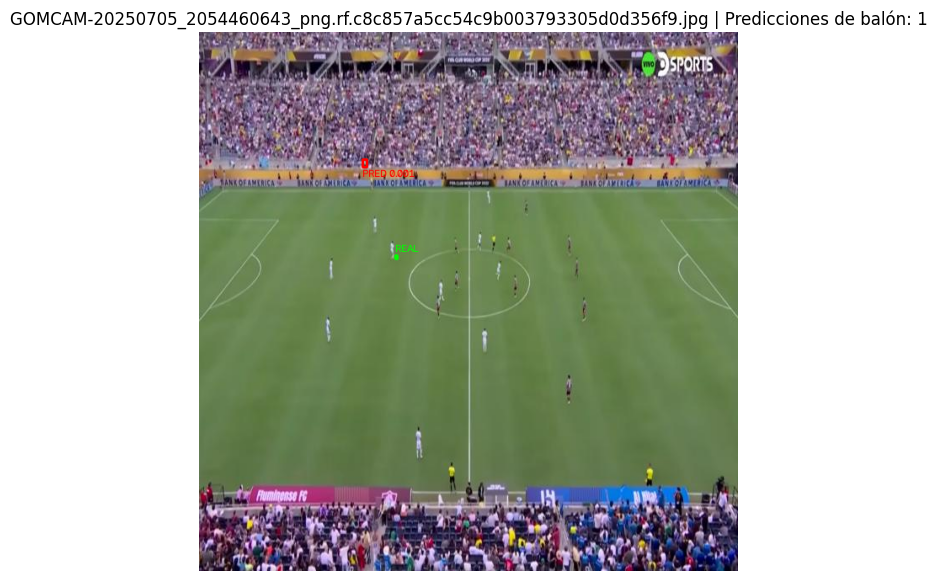

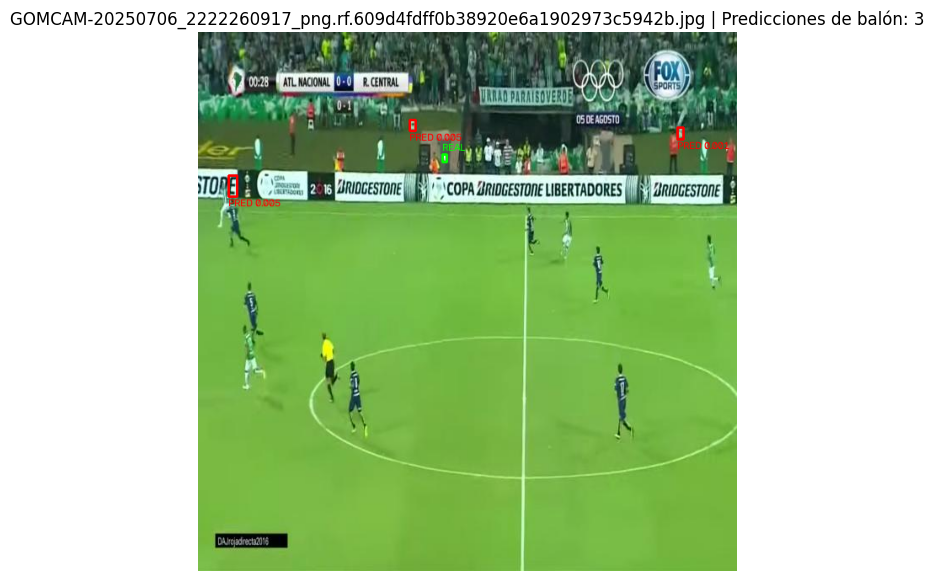

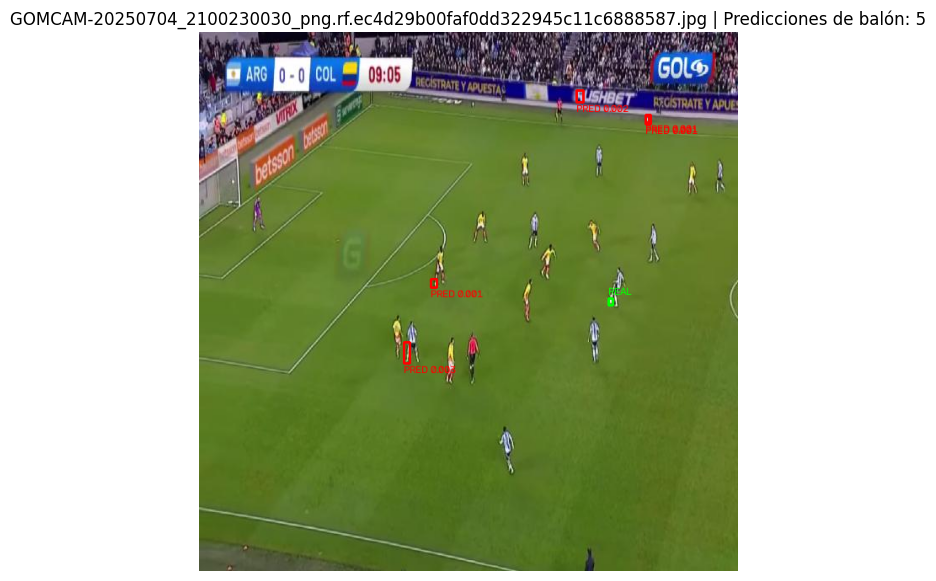

In [22]:
#Visualizar los 3 casos con mayor distancia

# ==================================================
# PASO 4 — INSPECCIÓN VISUAL DE LOS CASOS DIFÍCILES
# ==================================================

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

IMAGE_DIR = DATASET_DIR / "test" / "images"
LABEL_DIR = DATASET_DIR / "test" / "labels"

model = YOLO(str(MODEL_PATH))

difficult_names = [
    "GOMCAM-20250705_2054460643_png.rf.c8c857a5cc54c9b003793305d0d356f9.jpg",
    "GOMCAM-20250706_2222260917_png.rf.609d4fdff0b38920e6a1902973c5942b.jpg",
    "GOMCAM-20250704_2100230030_png.rf.ec4d29b00faf0dd322945c11c6888587.jpg"
]

for filename in difficult_names:
    image_path = IMAGE_DIR / filename
    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if not image_path.exists() or not label_path.exists():
        print("No se encuentra:", filename)
        continue

    image_bgr = cv2.imread(str(image_path))
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]
    visual = image.copy()

    # Anotaciones reales en verde
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) >= 5 and parts[0] == "3":
            _, xc, yc, bw, bh = map(float, parts[:5])
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(visual, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(
                visual, "REAL",
                (x1, max(12, y1 - 4)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1
            )

    # Predicciones con umbral bajo
    result = model.predict(
        source=image,
        imgsz=640,
        conf=0.001,
        classes=[3],
        verbose=False
    )[0]

    count = 0
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        conf = float(box.conf[0])
        cv2.rectangle(visual, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(
            visual, f"PRED {conf:.3f}",
            (x1, min(h - 3, y2 + 12)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1
        )
        count += 1

    plt.figure(figsize=(12, 7))
    plt.imshow(visual)
    plt.title(f"{filename} | Predicciones de balón: {count}")
    plt.axis("off")
    plt.show()


In [23]:
#Comprobar el tamaño real del balón

# ==================================================
# PASO 5 — MEDIR EL TAMAÑO REAL DEL BALÓN
# ==================================================

from pathlib import Path
import pandas as pd
import cv2

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"

IMAGE_DIR = DATASET_DIR / "test" / "images"
LABEL_DIR = DATASET_DIR / "test" / "labels"

rows = []

for label_path in LABEL_DIR.glob("*.txt"):
    image_path = next(
        (p for p in IMAGE_DIR.glob(label_path.stem + ".*")
         if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
        None
    )

    if image_path is None:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        continue

    h, w = image.shape[:2]

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5 or parts[0] != "3":
            continue

        _, xc, yc, bw, bh = map(float, parts[:5])

        rows.append({
            "imagen": image_path.name,
            "ancho_px": bw * w,
            "alto_px": bh * h,
            "area_px": bw * w * bh * h
        })

df_ball = pd.DataFrame(rows)

print("Anotaciones de balón:", len(df_ball))
print("\nTamaño de las cajas (píxeles):")
print(df_ball[["ancho_px", "alto_px", "area_px"]].describe().round(2))

print("\nBalones con ancho <= 5 px:",
      (df_ball["ancho_px"] <= 5).sum())
print("Balones con ancho <= 10 px:",
      (df_ball["ancho_px"] <= 10).sum())


Anotaciones de balón: 46

Tamaño de las cajas (píxeles):
       ancho_px  alto_px  area_px
count     46.00    46.00    46.00
mean       4.75     8.62    42.30
std        1.21     1.91    17.73
min        2.50     4.50    11.25
25%        4.00     7.50    29.81
50%        4.50     8.50    38.75
75%        5.50    10.00    54.38
max        7.50    12.50    90.00

Balones con ancho <= 5 px: 33
Balones con ancho <= 10 px: 46


In [24]:
#Probar el modelo con resolución de 1280 px
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

model = YOLO(str(MODEL_PATH))

resultados = []

for imgsz in [640, 1280]:
    metrics = model.val(
        data=str(DATASET_DIR / "data.yaml"),
        split="test",
        imgsz=imgsz,
        batch=4,
        device=0,
        classes=[3],
        plots=False,
        verbose=False
    )

    resultados.append({
        "resolucion": imgsz,
        "precision": round(metrics.box.mp, 4),
        "recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4)
    })

df_comparacion = pd.DataFrame(resultados)
display(df_comparacion)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1773.6±464.6 MB/s, size: 44.1 KB)
val: Scanning /content/scout/data/futdataset_v2/test/labels.cache... 52 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 9.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 11.0it/s 1.2s
                   all         52         46      0.725      0.459      0.498      0.199
Speed: 1.0ms preprocess, 15.7ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1865.9±671.5 MB/s, size: 46.5 KB)
val: Scanning /content/scout/data/futdataset_v2/test/lab

,resolucion,precision,recall,mAP50,mAP50-95
0,640,0.7254,0.4594,0.4982,0.1988
1,1280,0.7748,0.4783,0.4946,0.2020


In [25]:
#Comprobar qué aprende el modelo sobre el balón
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

model = YOLO(str(MODEL_PATH))

image_dir = DATASET_DIR / "test" / "images"
label_dir = DATASET_DIR / "test" / "labels"

rows = []

for label_path in sorted(label_dir.glob("*.txt")):
    has_ball = any(
        line.split()[0] == "3"
        for line in label_path.read_text().splitlines()
        if line.strip()
    )

    if not has_ball:
        continue

    image_path = next(
        (p for p in image_dir.glob(label_path.stem + ".*")
         if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
        None
    )

    if image_path is None:
        continue

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        classes=[3],
        verbose=False
    )[0]

    confidences = result.boxes.conf.cpu().tolist()

    rows.append({
        "imagen": image_path.name,
        "predicciones": len(confidences),
        "confianza_maxima": max(confidences) if confidences else 0.0
    })

df_ball_test = pd.DataFrame(rows)

print("Imágenes evaluadas:", len(df_ball_test))
print("Imágenes con alguna predicción:",
      (df_ball_test["predicciones"] > 0).sum())

print("\nDistribución de confianza máxima por imagen:")
print(
    df_ball_test["confianza_maxima"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(4)
)

print("\nImágenes sin predicción:",
      (df_ball_test["predicciones"] == 0).sum())

print("\nImágenes con confianza máxima inferior a 0.05:",
      (df_ball_test["confianza_maxima"] < 0.05).sum())

Imágenes evaluadas: 46
Imágenes con alguna predicción: 46

Distribución de confianza máxima por imagen:
count    46.0000
mean      0.3321
std       0.3009
min       0.0034
25%       0.0455
50%       0.2745
75%       0.6271
max       0.8703
Name: confianza_maxima, dtype: float64

Imágenes sin predicción: 0

Imágenes con confianza máxima inferior a 0.05: 13


In [26]:
#Medir si la predicción coincide con el balón real
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import cv2
import numpy as np

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

model = YOLO(str(MODEL_PATH))

image_dir = DATASET_DIR / "test" / "images"
label_dir = DATASET_DIR / "test" / "labels"

rows = []

for label_path in sorted(label_dir.glob("*.txt")):
    ball_labels = [
        line.split()
        for line in label_path.read_text().splitlines()
        if line.strip() and line.split()[0] == "3"
    ]

    if not ball_labels:
        continue

    image_path = next(
        (p for p in image_dir.glob(label_path.stem + ".*")
         if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
        None
    )
    if image_path is None:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        continue

    h, w = image.shape[:2]

    # Centro del balón anotado (coordenadas en píxeles)
    gt_centers = []
    for parts in ball_labels:
        _, xc, yc, bw, bh = map(float, parts[:5])
        gt_centers.append([xc * w, yc * h])

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        classes=[3],
        verbose=False
    )[0]

    if len(result.boxes):
        boxes = result.boxes.xyxy.cpu().numpy()
        confs = result.boxes.conf.cpu().numpy()
        pred_centers = np.column_stack((
            (boxes[:, 0] + boxes[:, 2]) / 2,
            (boxes[:, 1] + boxes[:, 3]) / 2
        ))

        distances = np.linalg.norm(
            np.array(gt_centers)[:, None, :] -
            pred_centers[None, :, :],
            axis=2
        )
        best_idx = np.unravel_index(np.argmin(distances), distances.shape)
        distance = float(distances[best_idx])
        confidence = float(confs[best_idx[1]])
    else:
        distance = np.nan
        confidence = np.nan

    rows.append({
        "imagen": image_path.name,
        "distancia_px": distance,
        "confianza_prediccion_cercana": confidence
    })

df_localizacion = pd.DataFrame(rows)

print("Imágenes evaluadas:", len(df_localizacion))
print("\nDistancia al centro de la anotación real:")
print(df_localizacion["distancia_px"].describe().round(2))

for threshold in [5, 10, 20]:
    n = (df_localizacion["distancia_px"] <= threshold).sum()
    print(f"Predicción a {threshold} px o menos: {n}/{len(df_localizacion)}")

print("\nEjemplos con mayor distancia:")
display(
    df_localizacion.sort_values("distancia_px", ascending=False).head(10)
)

Imágenes evaluadas: 46

Distancia al centro de la anotación real:
count     46.00
mean      44.13
std       75.60
min        0.29
25%        0.50
50%        1.04
75%       56.77
max      292.07
Name: distancia_px, dtype: float64
Predicción a 5 px o menos: 29/46
Predicción a 10 px o menos: 31/46
Predicción a 20 px o menos: 31/46

Ejemplos con mayor distancia:


,imagen,distancia_px,confianza_prediccion_cercana
26,GOMCAM-20250705_2054460643_png.rf.c8c857a5cc54...,292.065424,0.045435
29,GOMCAM-20250706_2222260917_png.rf.609d4fdff0b3...,253.134444,0.003273
7,GOMCAM-20250704_2100230030_png.rf.ec4d29b00faf...,210.764253,0.001052
13,GOMCAM-20250704_2114340449_png.rf.e958f5632f3d...,196.169282,0.003783
0,GOMCAM-20250704_2051270247_png.rf.0c6dccea6f06...,161.155766,0.008863
30,GOMCAM-20250706_2227070315_png.rf.aa665597c5f3...,151.736652,0.001259
34,GOMCAM-20250708_2214330201_png.rf.d4a04b96c2be...,115.903633,0.002078
4,GOMCAM-20250704_2054310355_png.rf.54765be1f034...,107.708324,0.001062
23,GOMCAM-20250705_2045020275_png.rf.7809f854507c...,102.891647,0.003180
44,GOMCAM-20250712_2233510129_png.rf.40da08a3c2ff...,99.606387,0.001555


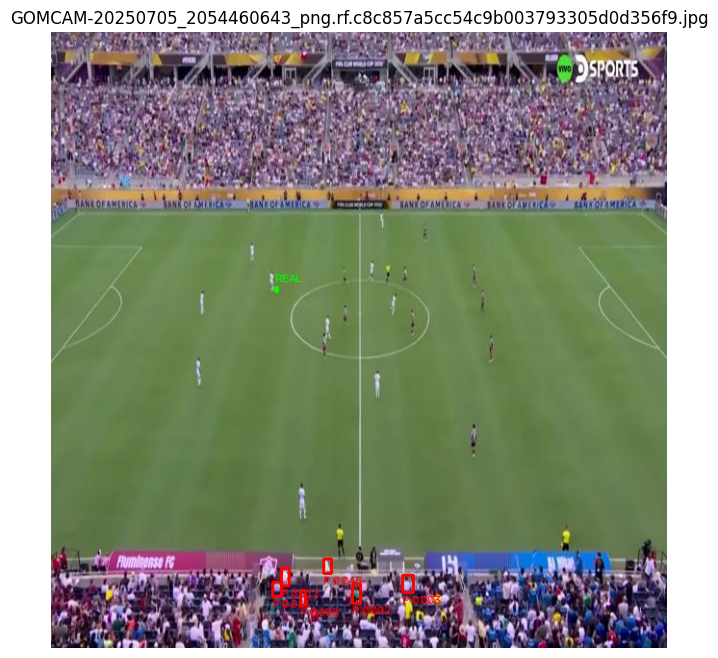

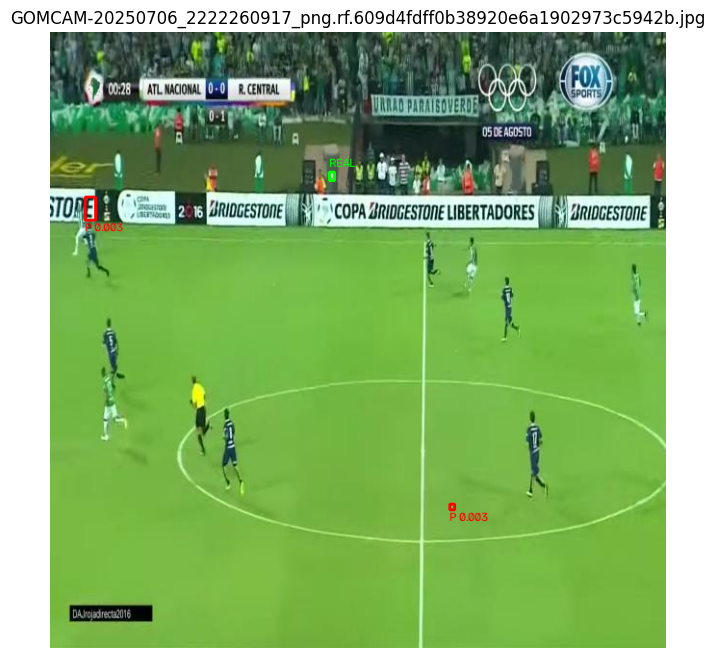

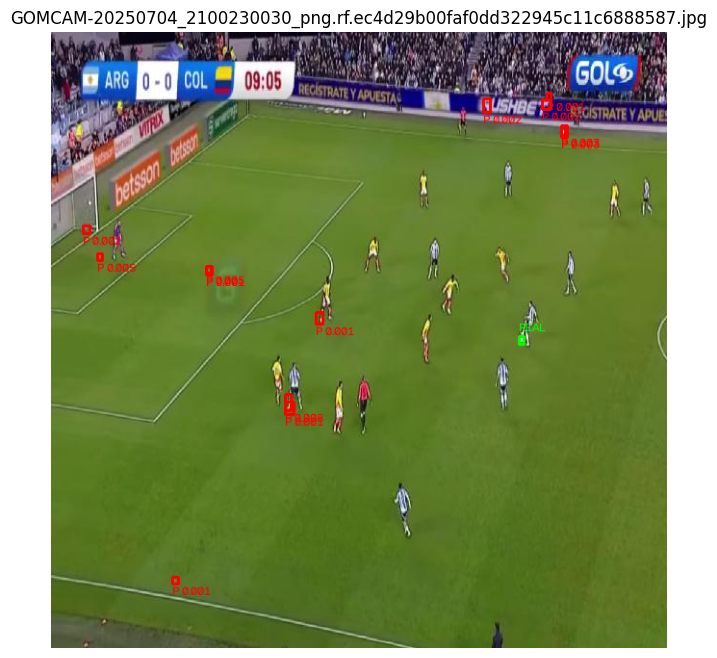

In [27]:
#Visualizar los errores reales
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

model = YOLO(str(MODEL_PATH))

# Tres imágenes con mayores distancias encontradas
worst_images = [
    "GOMCAM-20250705_2054460643_png.rf.c8c857a5cc54c9b003793305d0d356f9.jpg",
    "GOMCAM-20250706_2222260917_png.rf.609d4fdff0b38920e6a1902973c5942b.jpg",
    "GOMCAM-20250704_2100230030_png.rf.ec4d29b00faf0dd322945c11c6888587.jpg",
]

image_dir = DATASET_DIR / "test" / "images"
label_dir = DATASET_DIR / "test" / "labels"

for filename in worst_images:
    image_path = image_dir / filename
    label_path = label_dir / f"{image_path.stem}.txt"

    if not image_path.exists() or not label_path.exists():
        print("No se encontró:", filename)
        continue

    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]

    # Anotaciones reales en verde
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5 or parts[0] != "3":
            continue

        _, xc, yc, bw, bh = map(float, parts[:5])
        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image, "REAL", (x1, max(12, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)

    # Predicciones en rojo, con umbral bajo para ver candidatos
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        classes=[3],
        verbose=False
    )[0]

    for box, conf in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.conf.cpu().numpy()
    ):
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(image, f"P {conf:.3f}", (x1, min(h - 2, y2 + 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(14, 8))
    plt.imshow(image)
    plt.title(filename)
    plt.axis("off")
    plt.show()

In [28]:
#Revisar las anotaciones del balón
from pathlib import Path
import pandas as pd

DATASET_DIR = Path("/content/scout/data/futdataset_v2")
LABEL_DIR = DATASET_DIR / "train" / "labels"

rows = []
archivos_con_balón = 0

for label_path in LABEL_DIR.glob("*.txt"):
    tiene_balón = False

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        class_id, xc, yc, bw, bh = map(float, parts[:5])

        if class_id == 3:
            tiene_balón = True
            rows.append({
                "imagen": label_path.stem,
                "xc": xc,
                "yc": yc,
                "ancho": bw,
                "alto": bh,
                "coordenadas_validas": (
                    0 <= xc <= 1 and 0 <= yc <= 1
                    and 0 < bw <= 1 and 0 < bh <= 1
                )
            })

    if tiene_balón:
        archivos_con_balón += 1

df_train_ball = pd.DataFrame(rows)

print("Imágenes de entrenamiento con balón:", archivos_con_balón)
print("Anotaciones de balón:", len(df_train_ball))

if not df_train_ball.empty:
    print("\nCoordenadas válidas:")
    print(df_train_ball["coordenadas_validas"].value_counts())

    print("\nDistribución del tamaño normalizado:")
    print(df_train_ball[["ancho", "alto"]].describe().round(5))

Imágenes de entrenamiento con balón: 309
Anotaciones de balón: 309

Coordenadas válidas:
coordenadas_validas
True    309
Name: count, dtype: int64

Distribución del tamaño normalizado:
           ancho       alto
count  309.00000  309.00000
mean     0.00825    0.01410
std      0.00218    0.00340
min      0.00391    0.00625
25%      0.00703    0.01172
50%      0.00781    0.01406
75%      0.00938    0.01641
max      0.02188    0.02969


In [29]:
#Comprobar si el entrenamiento está penalizando la detección
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/scout")
RESULTS_CSV = (
    PROJECT_DIR
    / "outputs"
    / "deteccion_v1"
    / "results.csv"
)

print("¿Existe results.csv?:", RESULTS_CSV.exists())

if RESULTS_CSV.exists():
    df_results = pd.read_csv(RESULTS_CSV)
    df_results.columns = df_results.columns.str.strip()

    print("\nColumnas disponibles:")
    print(df_results.columns.tolist())

    print("\nPrimeras 3 épocas:")
    display(df_results.head(3))

    print("\nÚltimas 5 épocas:")
    display(df_results.tail(5))
else:
    print("No se encontró results.csv en esa ruta.")

¿Existe results.csv?: True

Columnas disponibles:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Primeras 3 épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,11.7802,1.44580,2.60828,0.97014,0.70440,0.34210,0.20921,0.14041,1.07009,2.06213,0.91196,0.000319,0.000319,0.000319
1,2,18.7253,1.26288,1.37115,0.90309,0.34940,0.58444,0.41636,0.22631,1.27830,2.19704,0.94164,0.000639,0.000639,0.000639
2,3,25.6846,1.21619,1.23018,0.89319,0.46629,0.60116,0.51223,0.30574,1.14816,1.70585,0.94094,0.000946,0.000946,0.000946



Últimas 5 épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,325.742,0.78495,0.44174,0.82563,0.84339,0.82071,0.84015,0.61533,0.78267,0.48670,0.84231,0.000109,0.000109,0.000109
46,47,332.364,0.78504,0.43721,0.81972,0.85734,0.80701,0.83463,0.61312,0.78341,0.49482,0.84156,0.000089,0.000089,0.000089
47,48,338.940,0.77058,0.42714,0.81927,0.87146,0.80534,0.84445,0.61735,0.77583,0.49300,0.84287,0.000069,0.000069,0.000069
48,49,345.388,0.77704,0.43021,0.82426,0.84562,0.81246,0.84251,0.61416,0.77987,0.48810,0.84425,0.000050,0.000050,0.000050
49,50,351.863,0.76141,0.42495,0.82049,0.85983,0.79546,0.84477,0.61531,0.77876,0.49199,0.84301,0.000030,0.000030,0.000030



results.png: existe = True


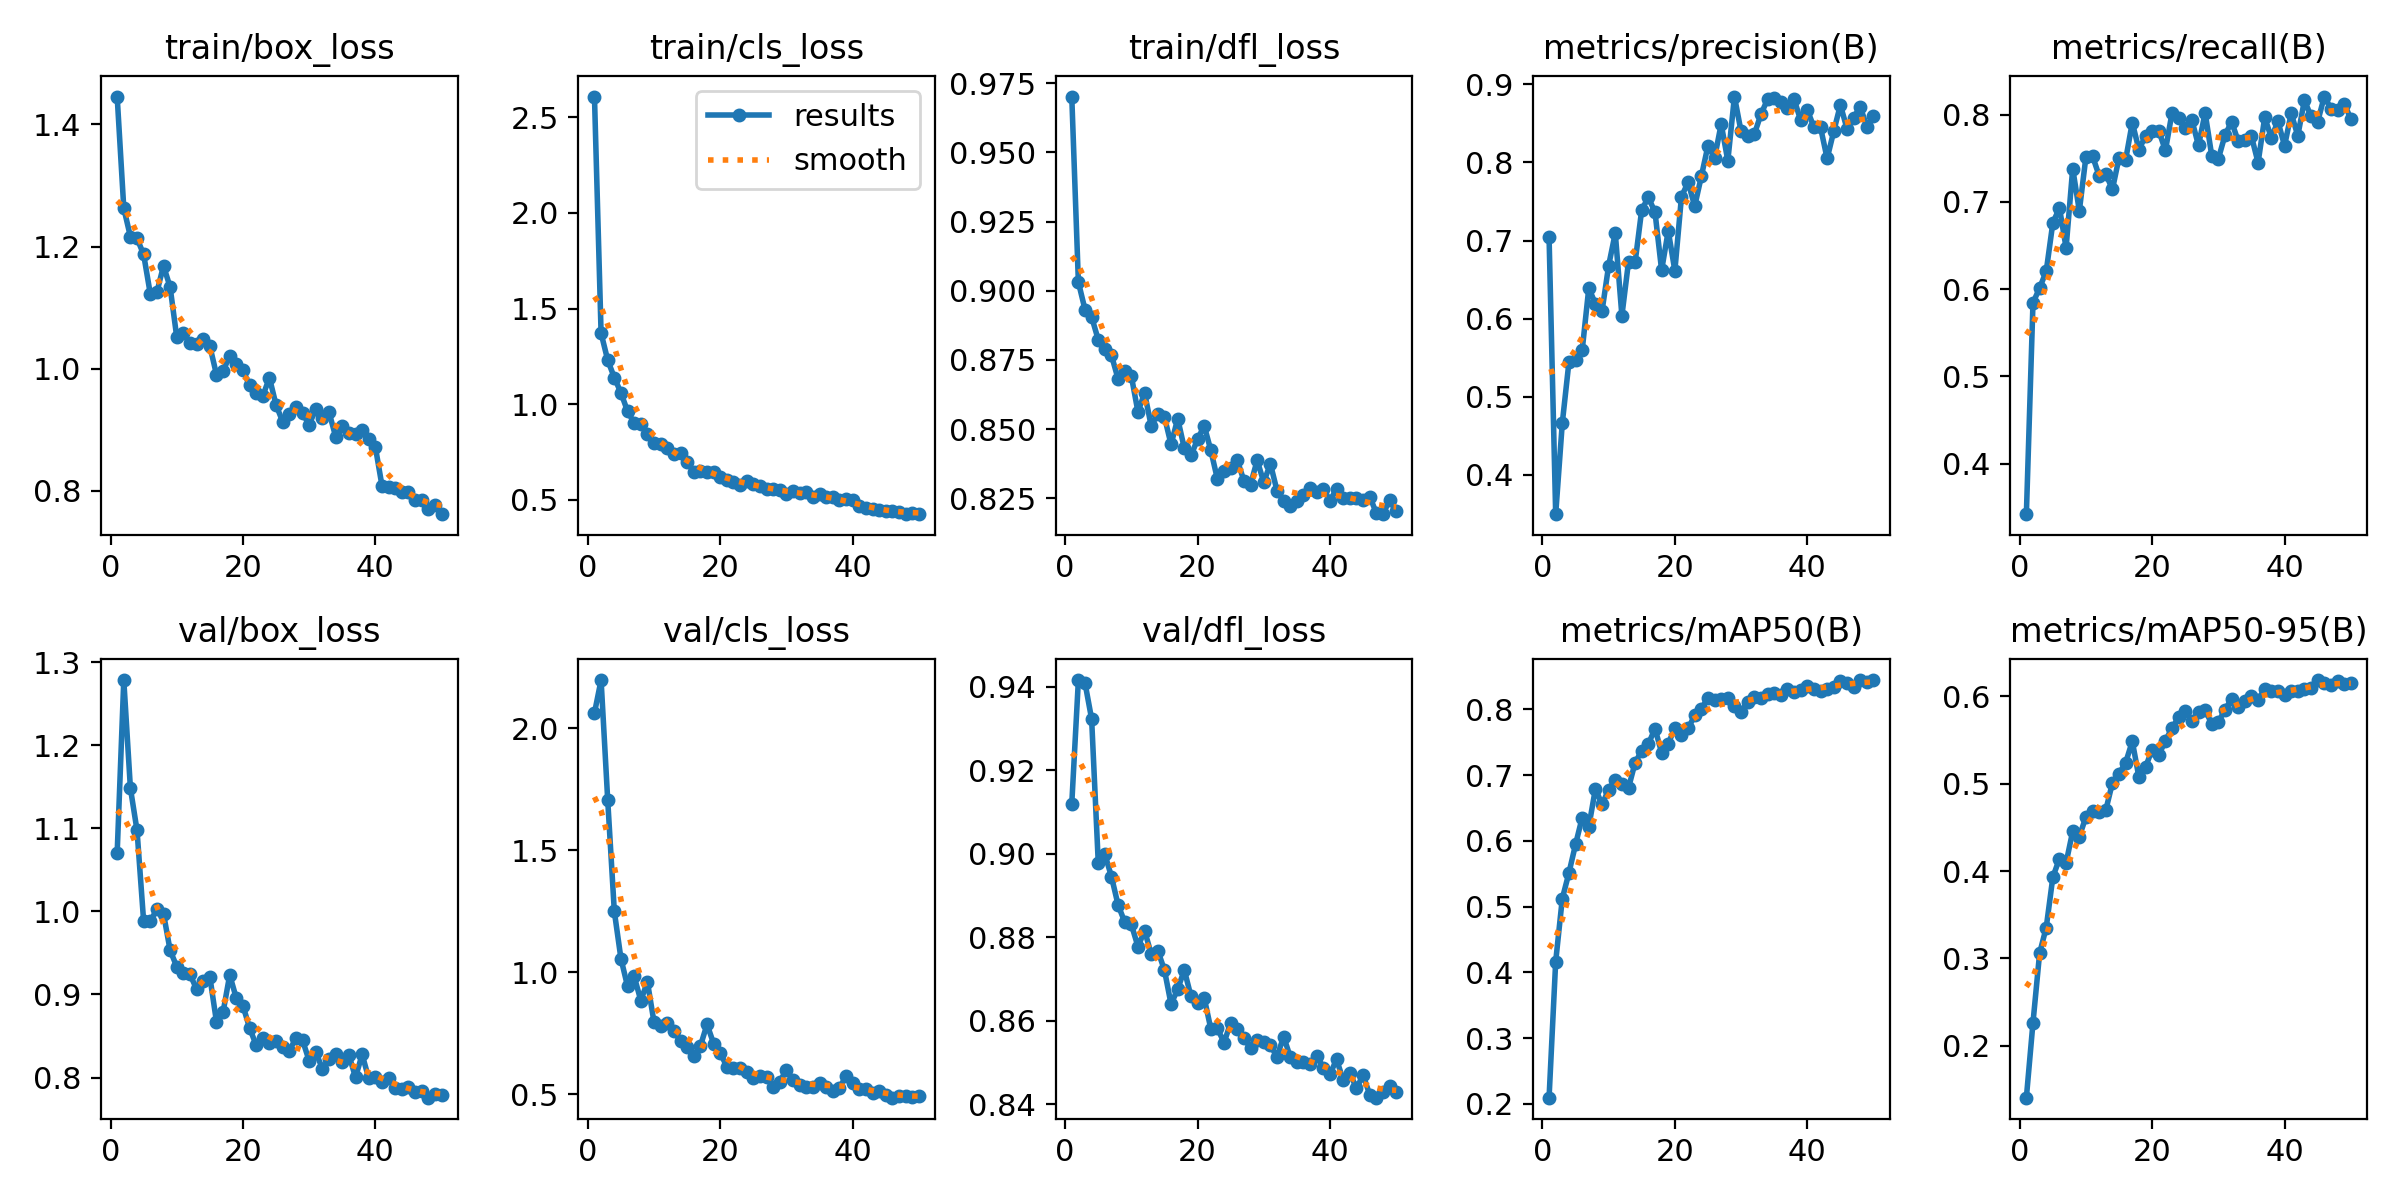


confusion_matrix.png: existe = True


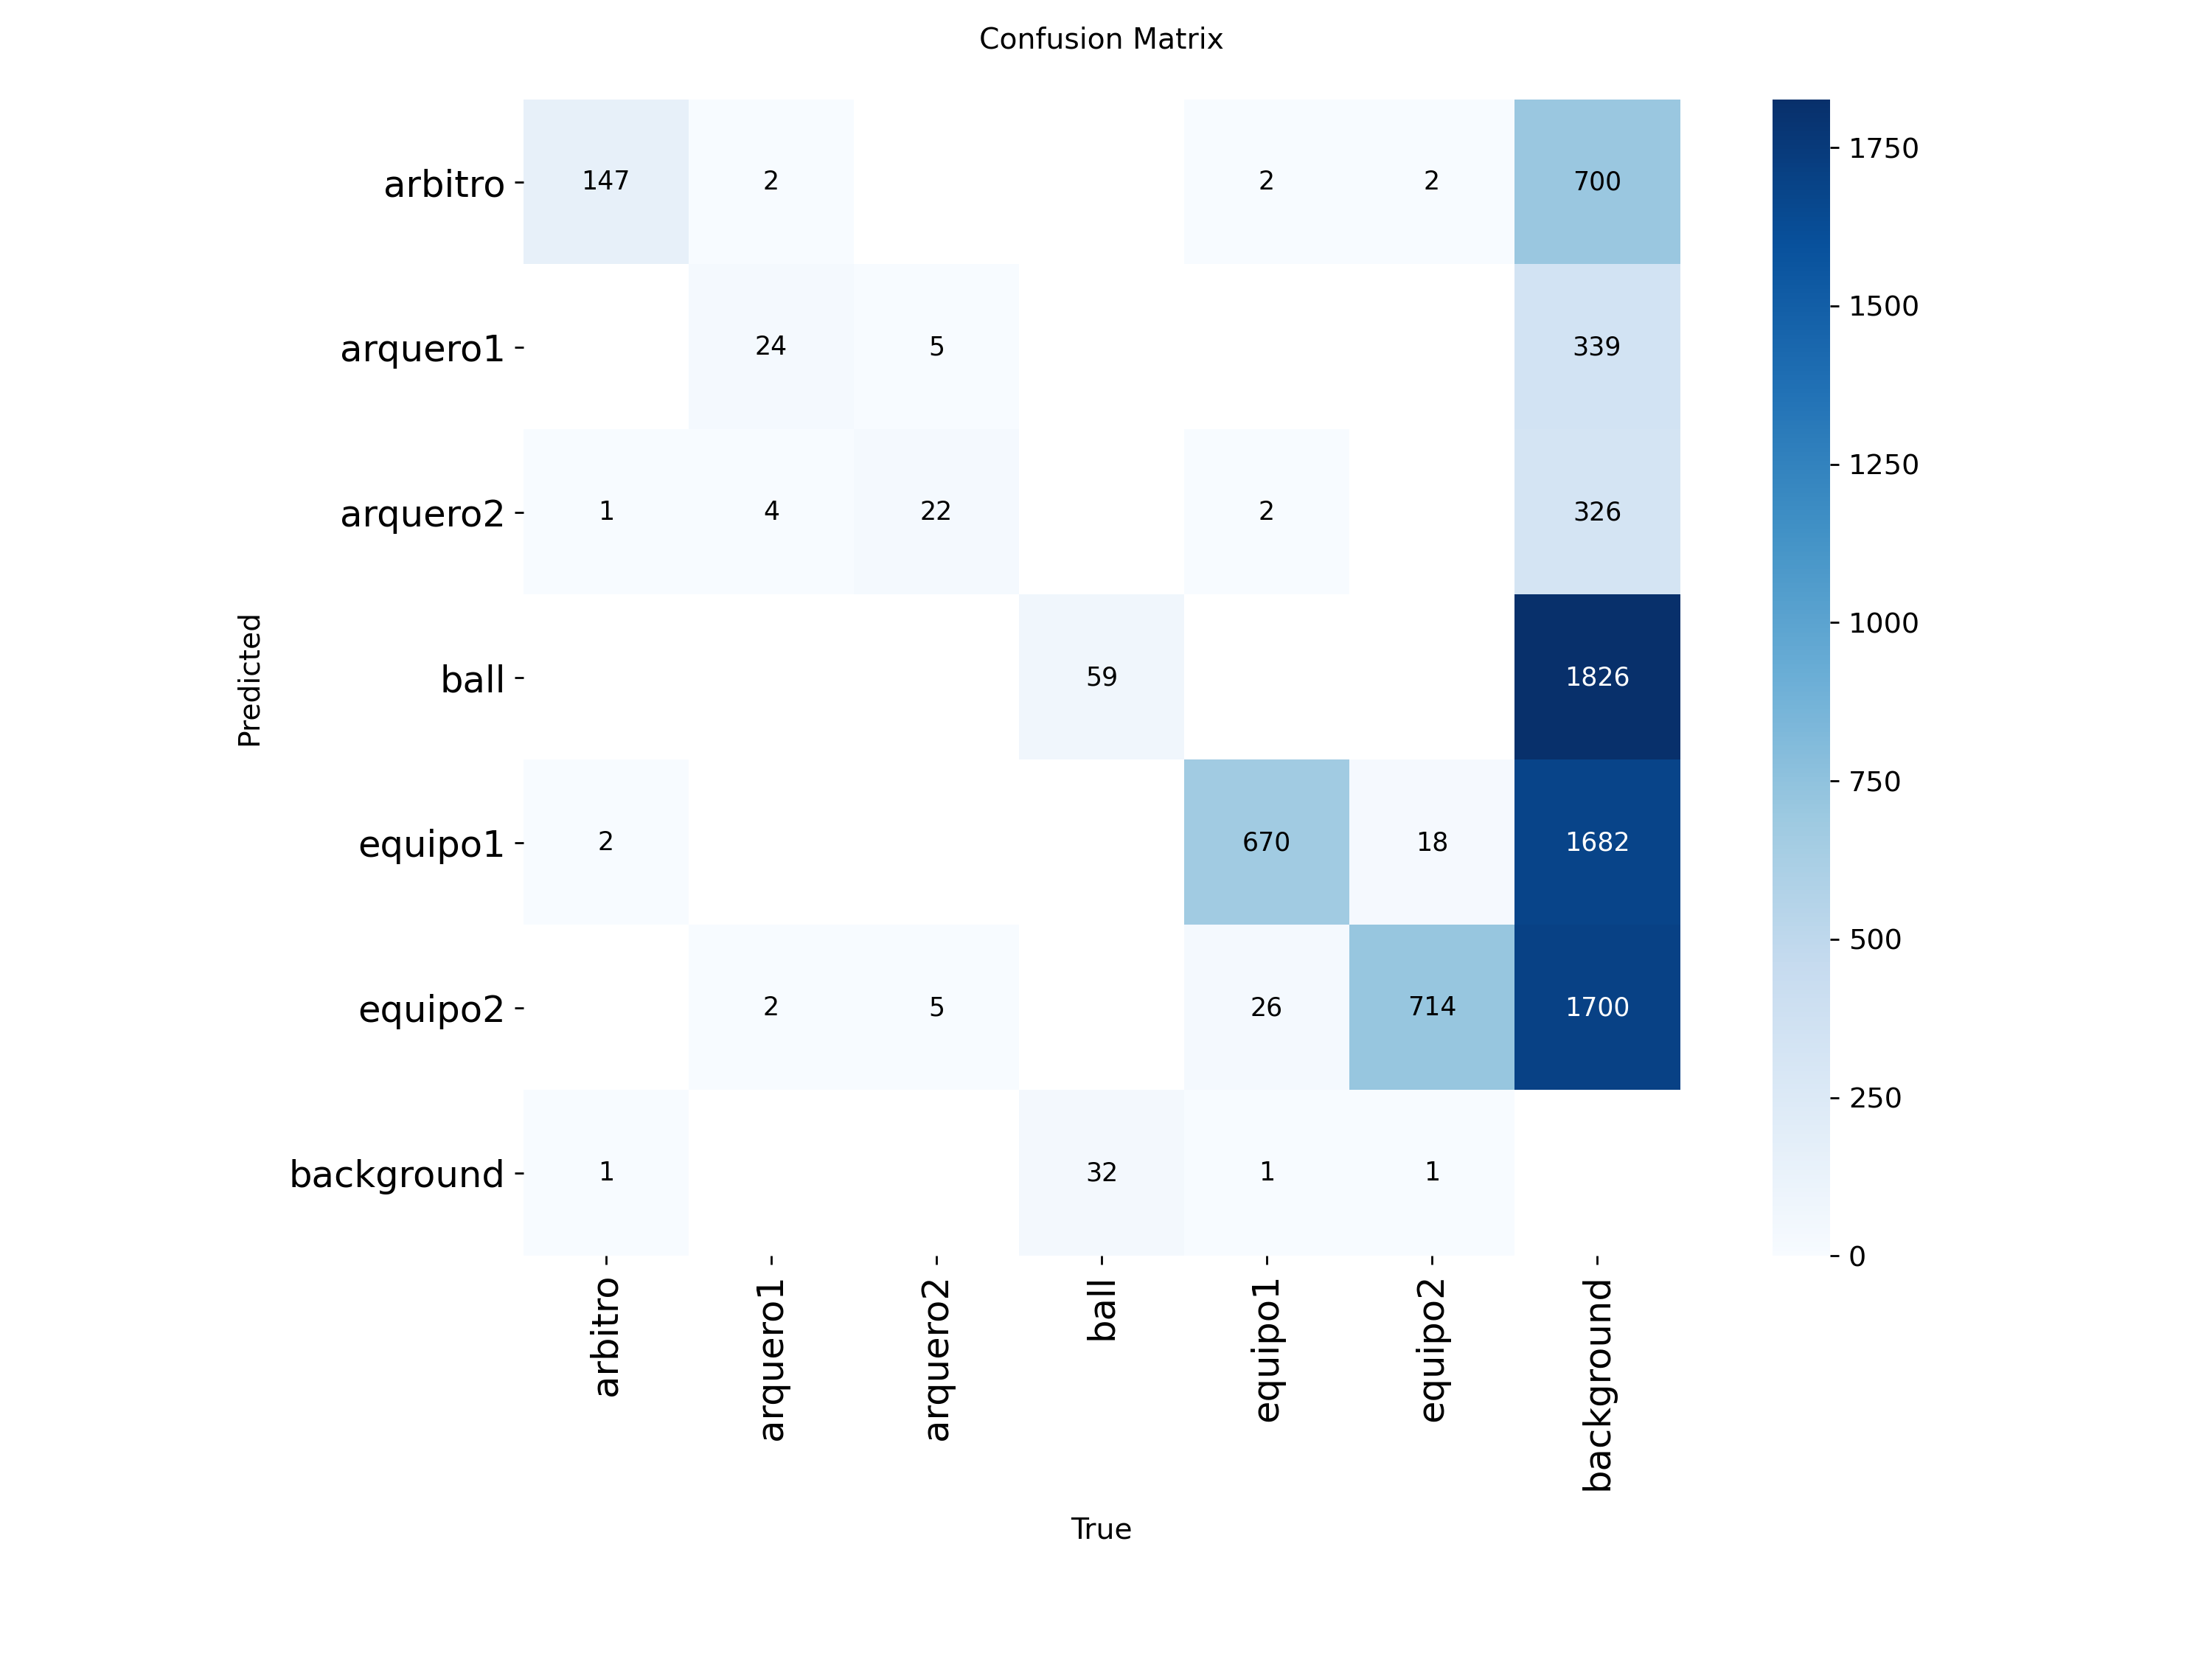


PR_curve.png: existe = False


In [30]:
#Revisar las curvas de entrenamiento
from pathlib import Path
from IPython.display import display, Image

PROJECT_DIR = Path("/content/scout")
RESULTS_DIR = PROJECT_DIR / "outputs" / "deteccion_v1"

for filename in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    image_path = RESULTS_DIR / filename

    print(f"\n{filename}: existe = {image_path.exists()}")

    if image_path.exists():
        display(Image(filename=str(image_path), width=900))